# Comparison of some models with the data

In [1]:
import sys
sys.path.append("../")
from utils import *

from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, make_scorer
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

from skopt import BayesSearchCV, gp_minimize, load
from skopt.plots import plot_objective, plot_convergence, plot_evaluations
from skopt.space import Space, Real, Integer, Categorical
from skopt.callbacks import CheckpointSaver

from joblib import Parallel, delayed

import warnings
warnings.filterwarnings("ignore")

## Importing data

In [2]:
suffix = "states_votes_incentives"
raw_data = pd.read_csv(f"../data/solar_panels_dataset_with_{suffix}.csv", index_col=0)

features = sorted(list(set(raw_data.columns) - {'state', 'cumulative num of residential PVs by 2016', 'number of buildings'}))

X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y!=0)

## XGBoost

In [3]:
xg_space = [
    Integer(10, 1000, name='n_estimators'),
    Integer(0, 50, name='max_leaves'),
    Real(1e-2, 10, prior='log-uniform', name='learning_rate'),
    Categorical([0, 5, 10, 15, 20, 25, 30, 35, 40], name='max_depth'),
]

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5)
all_scores = []

def cv_one(model, X, y, train_idx, test_idx):
    model.fit(X[train_idx], y[train_idx])
    y_pred = model.predict(X[test_idx])
    y_pred[np.isnan(y_pred)] = 1e20
    return r2_score(y[test_idx], y_pred)

def objective_xg(x):
    xc = x.copy()
    if xc[-1] == 0: xc[-1] = None
    params = {v: xv for v, xv in zip([v.name for v in xg_space], xc)}
    model = XGBRegressor(**params)
    scores = Parallel(n_jobs=8)(delayed(cv_one)(model, X_train, y_train, train, test) for train, test in rskf.split(X_train, y_train!=0))
    all_scores.append(scores)
    np.save(f"all_scores_{suffix}.npy", all_scores)

    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [ ]:
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
xg_opt = gp_minimize(objective_xg, xg_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_XG_{suffix}.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

In [ ]:
fig, ax = plt.subplots()

maxs = np.maximum.accumulate(-xg_opt.func_vals)
maxs = np.clip(maxs, 0.5, np.inf)
ax.plot(maxs, linewidth=3)

ax.set_xlabel("Iterations")
ax.set_ylabel("R2 score")
ax.grid()

fig.tight_layout()

In [ ]:
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)

print(f"Best CV score: {-xg_opt.func_vals.min():.4f}")
print(f"Test score: {model.score(X_test, y_test):.4f}")
print(f"Best params: {str(best_params)}")

With states: 0.6522

With states and votes: 0.7202

With states, votes, and incentives: 0.7188

In [ ]:
_ = plot_objective(xg_opt)
plt.show()

### Changing Train/test split

In [ ]:
raw_data = pd.read_csv("../data/solar_panels_dataset_with_states_votes_incentives.csv", index_col=0)
suffix = "states_votes_incentives"

features = set(raw_data.columns) - {'state', 'cumulative num of residential PVs by 2016', 'number of buildings'}

X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

In [ ]:
seeds = rng.integers(10000, size=(50))
scores = {}

for t in ['states', 'states_votes', 'states_votes_incentives']:
    print(t)
    
    scores[t] = []
    
    raw_data = pd.read_csv(f"../data/solar_panels_dataset_with_{t}.csv", index_col=0)

    features = set(raw_data.columns) - {'state', 'cumulative num of residential PVs by 2016', 'number of buildings'}

    X = raw_data[features].to_numpy()
    y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)
    
    xg_opt = load(f"opt_results_XG_{t}.pkl")
    best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
    best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
    model = XGBRegressor(**best_params)
    
    for s in seeds:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=s, stratify=y!=0)
        model.fit(X_train, y_train)
        scores[t].append(model.score(X_test, y_test))
        
    scores[t] = np.array(scores[t])

In [ ]:
one = scores['states_votes'] > scores['states']
two = scores['states_votes_incentives'] > scores['states_votes']
three = scores['states_votes_incentives'] >= 0.77
mask = one & two & three
{t: scores[t][mask] for t in scores.keys()}

In [ ]:
seeds[mask]

In [ ]:
{t: res_str(scores[t]) for t in scores.keys()}

In [ ]:
fig, ax = plt.subplots()

scores_to_plot = np.array(list(scores.values())).T
    
ax.boxplot(scores_to_plot)

ax.set_xticklabels(['states', '+ votes', '+ incentives'], rotation=45, ha='right', fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)
ax.tick_params(axis='y', labelsize=10)
ax.set_ylim(0.2)

fig.tight_layout()

### Best XGBoost

In [8]:
xg_opt = load(f"opt_results_XG_{suffix}.pkl")
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)
print(f"{model.score(X_test, y_test):.4f}")

0.7082


With states: 0.6505

With states and votes: 0.7124

With states, votes, and incentives: 0.7082

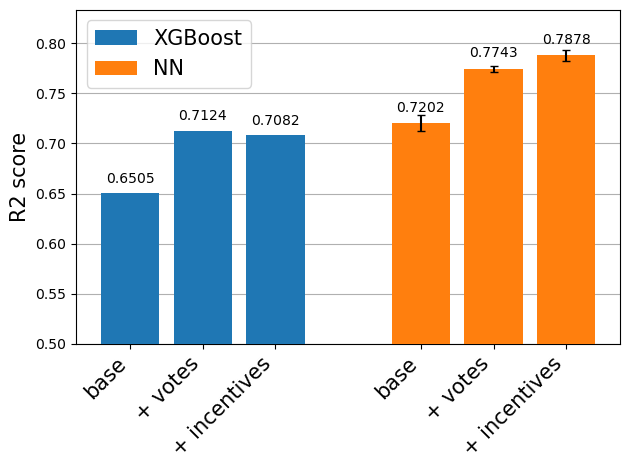

In [4]:
fig, ax = plt.subplots()

ax.bar([0, 1, 2], [0.6505, 0.7124, 0.7082], label="XGBoost", zorder=10)
ax.bar([4, 5, 6], [0.7202, 0.7743, 0.7878], yerr=[0.0080, 0.0033, 0.0057], label="NN", zorder=10, capsize=3)

for p, s in zip([0, 1, 2, 4, 5, 6], [0.6505, 0.7124, 0.7082, 0.7202, 0.7743, 0.7878]):
    ax.text(p, 1.015*s, s, ha='center')

ax.set_ylim(0.5)
ax.legend(fontsize=15)
ax.yaxis.grid(True)

ax.set_xticks([0, 1, 2, 4, 5, 6])
ax.set_xticklabels(["base", "+ votes", "+ incentives", "base", "+ votes", "+ incentives"], rotation=45, ha='right', fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)

fig.tight_layout()
# fig.savefig("../images/best_models_barplot.png", dpi=150)

### Best features

In [ ]:
features_plot = features
features_plot[:11] = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)',
            'fraction of dem votes',
            'level of incentives']

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_
feat_plot = np.array(features_plot)[importances.argsort()[-10:]]

ax.barh(range(len(feat_plot)), importances[importances.argsort()[-10:]])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_all_features.png", dpi=150)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_[:11]
feat_plot = np.array(features_plot[:11])[importances.argsort()]

ax.barh(range(len(feat_plot)), importances[importances.argsort()])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_features.png", dpi=150)

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.scatter(y_test, y_pred, zorder=10)
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax.set_ylim(minval, maxval)
ax.set_box_aspect(1)
ax.set_xscale('log')
ax.set_yscale('log')

fig.tight_layout()
# fig.savefig("XG_parity.png", dpi=150)

## NN

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader
import torch.utils.data as data_utils
device = 'cpu'

In [4]:
def train_model(model, X_train, y_train, X_val, y_val, lr=0.001, n_epochs=50, batch_size=32, verbose=False):
    #convert to tensors (for Pytorch)
    X_train_tensor = torch.tensor(X_train).to(device).float()
    y_train_tensor = torch.tensor(y_train).to(device).float()
    X_val_tensor = torch.tensor(X_val).to(device).float()
    y_val_tensor = torch.tensor(y_val).to(device).float()
    
    #intialize neural network
    n_samples, n_features = X_train_tensor.shape
    
    #initialize mse loss function
    criterion = torch.nn.MSELoss(reduction='mean')
    
    #keep track of losses
    train_losses = []
    val_losses = []
    train_r2 = []
    val_r2 = []
    
    #train with SGD
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    # scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.7)
    for e in range(n_epochs):
        model.train()
        y_pred = torch.zeros(y_train_tensor.shape).to(device)
        for batch_start in range(0, n_samples, batch_size):
            optimizer.zero_grad()
            X_batch = X_train_tensor[batch_start:batch_start+batch_size]
            y_batch = y_train_tensor[batch_start:batch_start+batch_size]
            y_pred_batch = model(X_batch)
            loss = criterion(y_pred_batch, y_batch)
            loss.backward()
            optimizer.step()
            y_pred[batch_start:batch_start+batch_size] = y_pred_batch
            
        train_losses.append(criterion(y_pred, y_train_tensor).item())
        y_pred = y_pred.detach().cpu().numpy()
        nanmask = ~np.isnan(y_pred)
        train_r2.append(r2_score(y_train[nanmask], y_pred[nanmask]))
        
        #evaluate model:
        model.eval()
        with torch.no_grad():
            y_pred = model(X_val_tensor)
            val_losses.append(criterion(y_pred, y_val_tensor).item())
            y_pred = y_pred.detach().cpu().numpy()
            nanmask = ~np.isnan(y_pred)
            val_r2.append(r2_score(y_val[nanmask], y_pred[nanmask]))
        
        if verbose and e%(n_epochs//5) == 0:
            print(f"[{e}] Train loss: {train_losses[e]:.4f} ({train_r2[e]:.4f}), Val loss: {val_losses[e]:.4f} ({val_r2[e]:.4f})")
            
        scheduler.step()
      
    if verbose:
        print(f"[{e}] Train loss: {train_losses[e]:.4f} ({train_r2[e]:.4f}), Val loss: {val_losses[e]:.4f} ({val_r2[e]:.4f})")
    
    return model, np.array(train_losses), np.array(val_losses), np.array(train_r2), np.array(val_r2)

def build_model(layer_1, layer_2, activation, final_relu):
    
    act_fct = None
    if activation=='relu':
        act_fct = nn.ReLU()
    elif activation=='tanh':
        act_fct = nn.Tanh()
    elif activation=='sigmoid':
        act_fct = nn.Sigmoid()
    else:
        raise Exception(f"The activation function must be one of relu, tanh, or sigmoid, not {activation}")
        
    layers = [nn.Linear(X_train.shape[1], layer_1), act_fct]
    
    if layer_2>0:
        layers.extend([nn.Linear(layer_1, layer_2), act_fct, nn.Linear(layer_2, 1)])
    else:
        layers.append(nn.Linear(layer_1, 1))
    
    if final_relu==True or final_relu=="final_relu":
        layers.append(nn.ReLU())
    
    return nn.Sequential(*layers).to(device)

def one_cv_nn(params):
    model = build_model(layer_1=params[0], layer_2=params[1], activation=params[2], final_relu=params[3])
    
    #random train, val split
    X_train_t, X_train_v, y_train_t, y_train_v = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train!=0)
    
    X_scaler = StandardScaler().fit(X_train_t)
    X_train_t = X_scaler.transform(X_train_t)
    X_train_v = X_scaler.transform(X_train_v)

    y_scaler = StandardScaler().fit(y_train_t)
    y_train_t = y_scaler.transform(y_train_t)
    y_train_v = y_scaler.transform(y_train_v)

    try:
        model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=params[4], n_epochs=500, verbose=False)
        mx = np.nanmax(val_r2)
    except Exception as e:
        mx = 0
    
    return mx

def objective_nn(params):
    paramsc = params.copy()
    paramsc[3] = True if params[3]=='final_relu' else False
    
    scores = Parallel(n_jobs=8)(delayed(one_cv_nn)(paramsc) for _ in range(16))

    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [5]:
nn_space = [
    Categorical([20, 30, 40, 50, 60, 70, 80, 90, 100], name='layer_1'),
    Categorical([0, 10, 20, 30, 40, 50], name='layer_2'),
    Categorical(['relu', 'tanh', 'sigmoid'], name='activation'),
    Categorical(['final_relu', 'no_final_relu'], name='final_relu'),
    Real(1e-6, 1e-1, prior='log-uniform', name='learning_rate'),
]
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
nn_opt = gp_minimize(objective_nn, nn_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_NN_{suffix}.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

Iteration 100/100, ETA: 19:57:21 (average time per iteration: 45.417s)


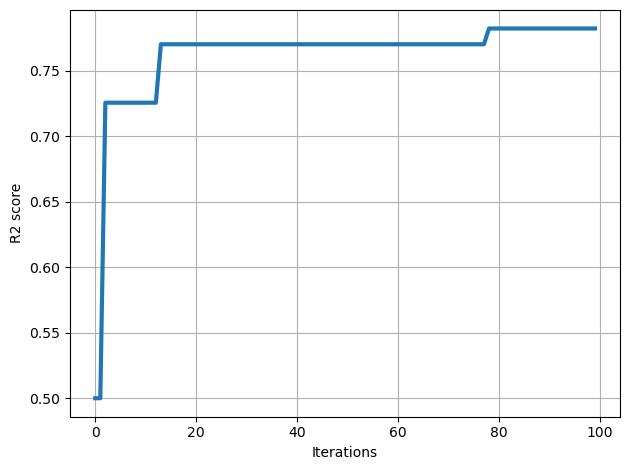

In [6]:
fig, ax = plt.subplots()

maxs = np.maximum.accumulate(-nn_opt.func_vals)
maxs = np.clip(maxs, 0.5, np.inf)
ax.plot(maxs, linewidth=3)

ax.set_xlabel("Iterations")
ax.set_ylabel("R2 score")
ax.grid()

fig.tight_layout()

In [7]:
best_x = nn_opt.x_iters[nn_opt.func_vals.argmin()]
print(f"Best params: {best_x}")

X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

model = build_model(*best_x[:-1])

n_epochs = 1000

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=best_x[-1], n_epochs=n_epochs, verbose=True)
print(f"Final test R2: {val_r2[-1]:.4f}")

Best params: [100, 0, 'sigmoid', 'no_final_relu', 0.01711126260505375]
[0] Train loss: 0.9101 (0.0899), Val loss: 0.6801 (0.2174)
[200] Train loss: 0.1804 (0.8196), Val loss: 0.1990 (0.7711)
[400] Train loss: 0.1640 (0.8360), Val loss: 0.1985 (0.7715)
[600] Train loss: 0.1605 (0.8395), Val loss: 0.1984 (0.7717)
[800] Train loss: 0.1596 (0.8404), Val loss: 0.1985 (0.7716)
[999] Train loss: 0.1594 (0.8406), Val loss: 0.1985 (0.7716)
Final test R2: 0.7716


In [26]:
class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

model = BestSVI()

n_epochs = 100

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=True)

[0] Train loss: 0.7459 (0.2541), Val loss: 0.3919 (0.5490)
[20] Train loss: 0.2468 (0.7532), Val loss: 0.1865 (0.7854)
[40] Train loss: 0.1932 (0.8068), Val loss: 0.1750 (0.7987)
[60] Train loss: 0.1642 (0.8358), Val loss: 0.1749 (0.7988)
[80] Train loss: 0.1505 (0.8495), Val loss: 0.1756 (0.7979)
[99] Train loss: 0.1401 (0.8599), Val loss: 0.1768 (0.7966)


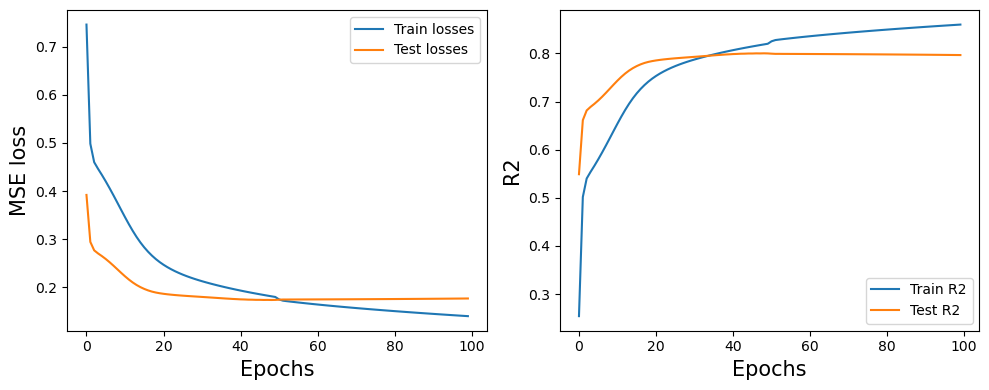

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(train_losses, label="Train losses")
ax[0].plot(val_losses, label="Test losses")

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

ax[1].plot(train_r2, label="Train R2")
ax[1].plot(val_r2, label="Test R2")

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

### Best NN different init same train/test

In [39]:
class BestS(nn.Module):
    def __init__(self):
        super(BestS, self).__init__()
        self.fc1 = nn.Linear(57, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 1)
        self.lr = 0.011012775071632105

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
class BestSV(nn.Module):
    def __init__(self):
        super(BestSV, self).__init__()
        self.fc1 = nn.Linear(58, 100)
        self.fc2 = nn.Linear(100, 1)
        self.lr = 0.01711126260505375

    def forward(self, x):
        x = F.sigmoid(self.fc1(x))
        x = self.fc2(x)
        return x

class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

In [29]:
X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

In [34]:
def one_train(i):
    model = BestSVI()
    
    _, train_loss, val_loss, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=False)
    
    return train_loss, val_loss, train_r2, val_r2

n_epochs = 150
n = 8*2

res = Parallel(n_jobs=8)(delayed(one_train)(i) for i in range(n))

train_losses = np.array(res)[:,0]
val_losses = np.array(res)[:,1]
train_r2s = np.array(res)[:,2]
val_r2s = np.array(res)[:,3]

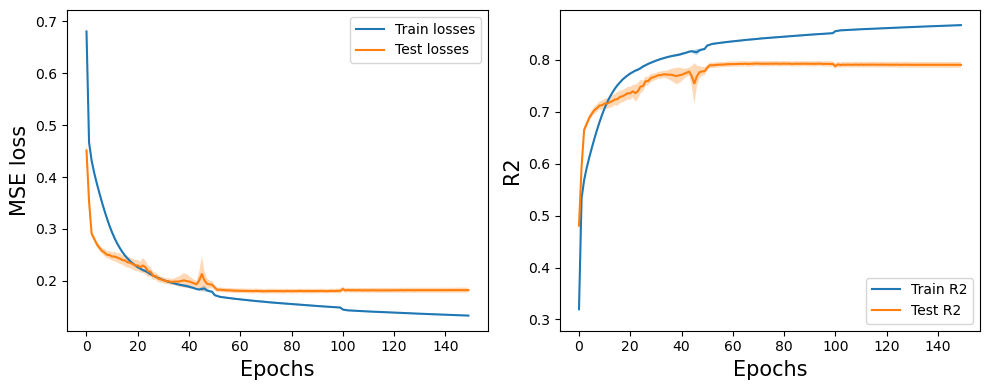

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

means = train_losses.mean(axis=0)
std_err = train_losses.std(axis=0)/np.sqrt(len(train_losses))
ax[0].plot(means, label="Train losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_losses.mean(axis=0)
std_err = val_losses.std(axis=0)/np.sqrt(len(val_losses))
ax[0].plot(means, label="Test losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

means = train_r2s.mean(axis=0)
std_err = train_r2s.std(axis=0)/np.sqrt(len(train_r2s))
ax[1].plot(means, label="Train R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_r2s.mean(axis=0)
std_err = val_r2s.std(axis=0)/np.sqrt(len(val_r2s))
ax[1].plot(means, label="Test R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)
# ax[1].plot(val_r2s.T, c='k', alpha=0.3, zorder=-1)

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

In [36]:
res_str(val_r2s[:,means.argmax()])

'0.7928 ± 0.0050'

With states: 0.7202 ± 0.0039

With states and votes: 0.7743 ± 0.0016

With states, votes, and incentives: 0.7878 ± 0.0028

### Best NN different train/test

In [14]:
class BestS(nn.Module):
    def __init__(self):
        super(BestS, self).__init__()
        self.fc1 = nn.Linear(57, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 1)
        self.lr = 0.011012775071632105

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
class BestSV(nn.Module):
    def __init__(self):
        super(BestSV, self).__init__()
        self.fc1 = nn.Linear(58, 100)
        self.fc2 = nn.Linear(100, 1)
        self.lr = 0.01711126260505375

    def forward(self, x):
        x = F.sigmoid(self.fc1(x))
        x = self.fc2(x)
        return x

class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

In [15]:
def one_train(i):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y!=0)

    X_scaler = StandardScaler().fit(X_train)
    X_train_t = X_scaler.transform(X_train)
    X_train_v = X_scaler.transform(X_test)

    y_scaler = StandardScaler().fit(y_train)
    y_train_t = y_scaler.transform(y_train)
    y_train_v = y_scaler.transform(y_test)
    
    model = BestSVI()
    
    _, train_loss, val_loss, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=False)
    
    return train_loss, val_loss, train_r2, val_r2

n_epochs = 200
n = 8*4

res = Parallel(n_jobs=8)(delayed(one_train)(i) for i in range(n))

train_losses = np.array(res)[:,0]
val_losses = np.array(res)[:,1]
train_r2s = np.array(res)[:,2]
val_r2s = np.array(res)[:,3]

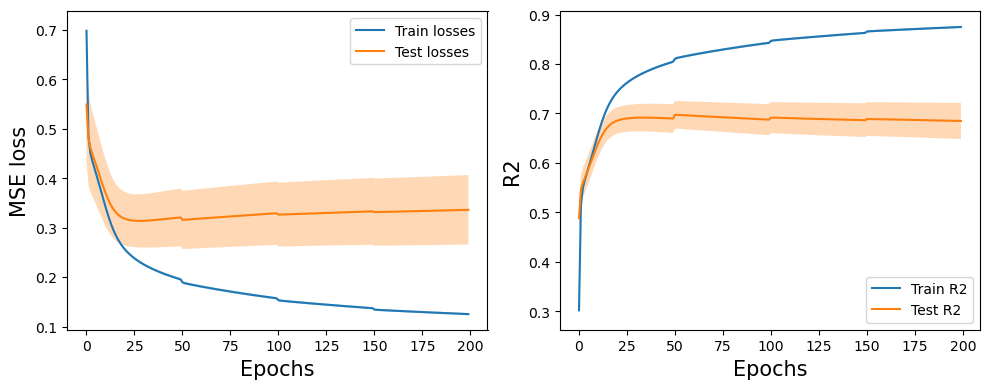

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

means = train_losses.mean(axis=0)
std_err = train_losses.std(axis=0)/np.sqrt(len(train_losses))
ax[0].plot(means, label="Train losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_losses.mean(axis=0)
std_err = val_losses.std(axis=0)/np.sqrt(len(val_losses))
ax[0].plot(means, label="Test losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

means = train_r2s.mean(axis=0)
std_err = train_r2s.std(axis=0)/np.sqrt(len(train_r2s))
ax[1].plot(means, label="Train R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_r2s.mean(axis=0)
std_err = val_r2s.std(axis=0)/np.sqrt(len(val_r2s))
ax[1].plot(means, label="Test R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)
# ax[1].plot(val_r2s.T, c='k', alpha=0.3, zorder=-1)

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

In [17]:
res_str(val_r2s[:,means.argmax()])

'0.6972 ± 0.0279'

In [18]:
mask = val_r2s[:,:20].min(axis=1)>=0
means = val_r2s[mask].mean(axis=0)
res_str(val_r2s[mask,means.argmax()])

'0.6972 ± 0.0279'

With states: 0.6675 ± 0.0374

With states and votes: 0.6661 ± 0.0302 (0.7000 ± 0.0434)

With states, votes, and incentives: 0.7305 ± 0.0346

### Removing features

In [5]:
from sklearn.feature_selection import SelectKBest, f_regression

In [6]:
def one_cv_nn_k(k, model):
    #random train, val split
    X_train_t, X_train_v, y_train_t, y_train_v = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train!=0)

    X_scaler = StandardScaler().fit(X_train_t)
    X_train_t = X_scaler.transform(X_train_t)
    X_train_v = X_scaler.transform(X_train_v)

    y_scaler = StandardScaler().fit(y_train_t)
    y_train_t = y_scaler.transform(y_train_t)
    y_train_v = y_scaler.transform(y_train_v)

    sel = SelectKBest(f_regression, k=k).fit(X_train_t, y_train_t)
    X_train_t = sel.transform(X_train_t)
    X_train_v = sel.transform(X_train_v)
    
    try:
        _, _, _, _, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=300, verbose=False)
        mx = np.nanmax(val_r2)
    except Exception as e:
        print(e)
        mx = 0
    
    return mx

In [7]:
ks = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, X.shape[1]]
scores = []

timer = IterTimer(len(ks))

for k in ks:
    timer.start_iter()
    
    class BestSVI(nn.Module):
        def __init__(self):
            super(BestSVI, self).__init__()
            self.fc1 = nn.Linear(k, 80)
            self.fc2 = nn.Linear(80, 1)
            self.lr = 0.012445653671345749

        def forward(self, x):
            x = F.tanh(self.fc1(x))
            x = self.fc2(x)
            return x
    
    score = Parallel(n_jobs=8)(delayed(one_cv_nn_k)(k, BestSVI()) for _ in range(24))
    scores.append(score)
    timer.end_iter()
    
scores = np.array(scores)

Iteration 12/12, ETA: 17:08:32 (average time per iteration: 33.003s)


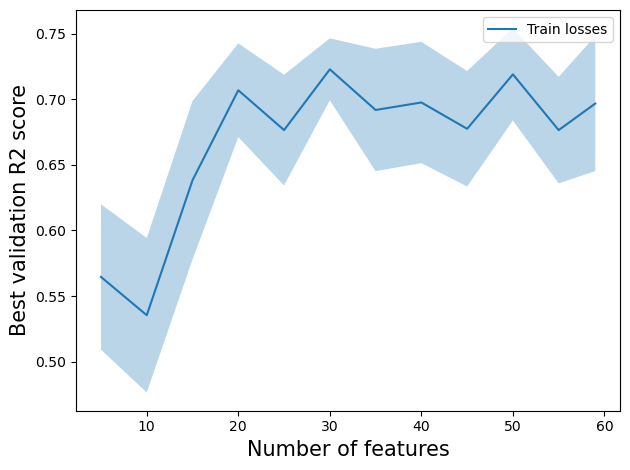

In [9]:
fig, ax = plt.subplots()

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(len(scores[0]))
ax.plot(ks, means, label="Train losses")
ax.fill_between(ks, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax.set_xlabel('Number of features', fontsize=15)
ax.set_ylabel('Best validation R2 score', fontsize=15)
ax.tick_params(labelsize=10)
ax.legend()

fig.tight_layout()
# fig.savefig("k_features_BestSVI.png", dpi=150)

### SHAP

In [60]:
import shap

features_simple = np.copy(features)
features_simple[:11] = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)',
            'fraction of dem votes',
            'level of incentives']

class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x
    
model = BestSVI()
model.load_state_dict(torch.load("BestSVI_0.7889"))

def m_for_shap(X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X).float()).numpy()
    
X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

In [7]:
explainer = shap.Explainer(m_for_shap, X_train_v)
shap_values = explainer(X_train_v)

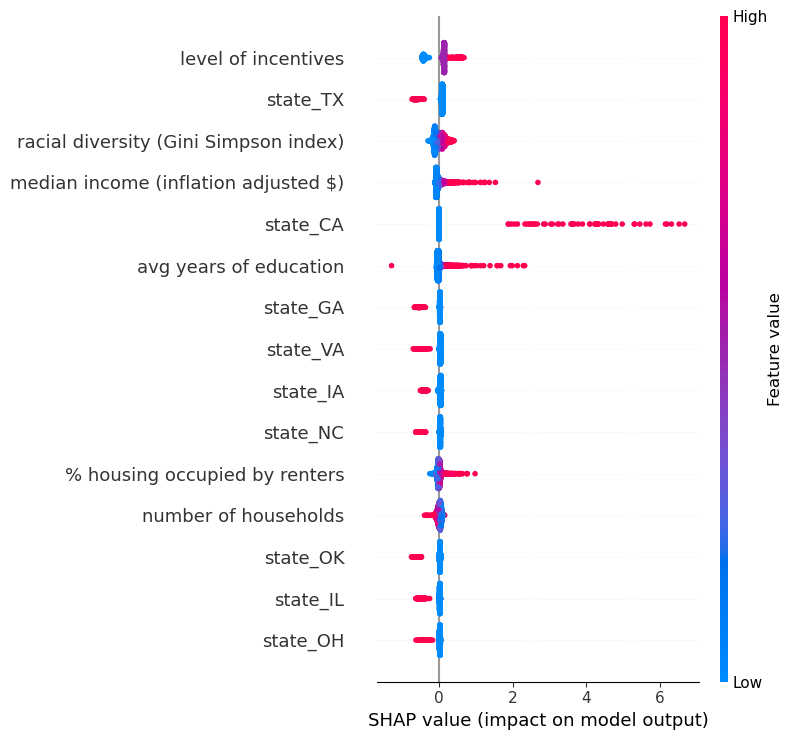

In [62]:
shap.summary_plot(shap_values, feature_names=features_simple, max_display=15, show=False)
# plt.savefig("../images/shap_values.png", dpi=150)

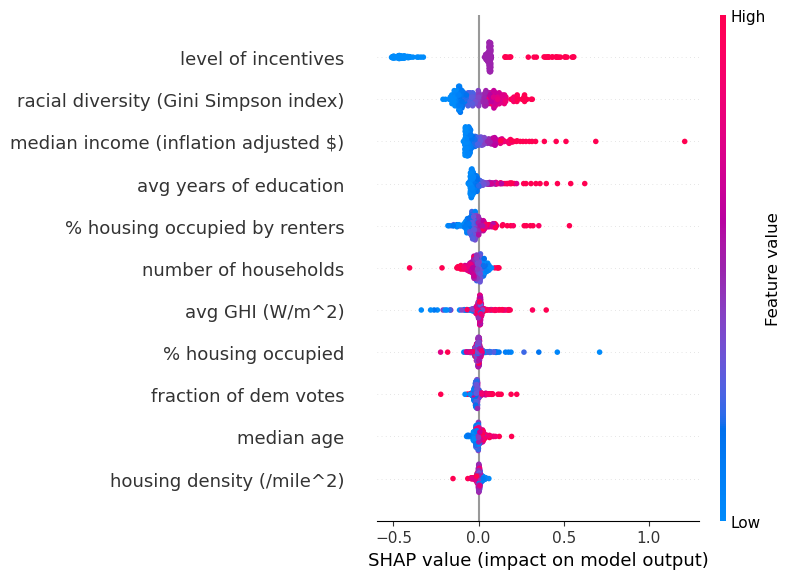

In [9]:
shap.summary_plot(shap_values[:,:11], feature_names=features_simple[:11], max_display=11, show=False)
plt.savefig("../images/shap_values_focused.png", dpi=150)

In [32]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import ttest_ind

In [161]:
# states = list(states_dict.values())
# shaps = {}

# timer = IterTimer(len(states))

# for s in states:
#     timer.start_iter()
    
#     subset = raw_data[raw_data['state']==s]
    
#     if len(subset)>=20:
#         features = sorted(list(set(subset.columns) - {'state', 'cumulative num of residential PVs by 2016', 'number of buildings'}))

#         X_state = subset[features].to_numpy()
#         y_state = (subset['cumulative num of residential PVs by 2016']/subset['number of buildings']).to_numpy().reshape(-1,1)
        
#         X_state = StandardScaler().fit_transform(X_state)

#         explainer = shap.Explainer(m_for_shap, X_state)
#         shap_values = explainer(X_state)
        
#         mean_shap = np.abs(shap_values.values).mean(axis=0)
#         shaps[s] = mean_shap[:10]
        
#     timer.end_iter()
    
# shap_vals = np.array(list(shaps.values()))

Iteration 53/53, ETA: 00:22:53 (average time per iteration: 0.862s)


In [11]:
explainer = shap.Explainer(m_for_shap, StandardScaler().fit_transform(X))
shap_values = explainer(StandardScaler().fit_transform(X))

Permutation explainer: 3105it [00:42, 57.28it/s]                                                                       


In [12]:
states = list(states_dict.values())
shaps = {}

for s in states:
    mask = raw_data['state']==s
    
    if mask.sum()>20:
        shaps[s] = shap_values.values[mask].mean(axis=0)[:10]
        
shap_vals = np.array(list(shaps.values()))

In [46]:
km = KMeans(n_clusters=3)
clusters = km.fit_predict(shap_vals)

pca = PCA(n_components=2)
shap_vals_proj = pca.fit_transform(shap_vals)

tsne = TSNE(n_components=2)
shap_vals_proj = tsne.fit_transform(shap_vals)

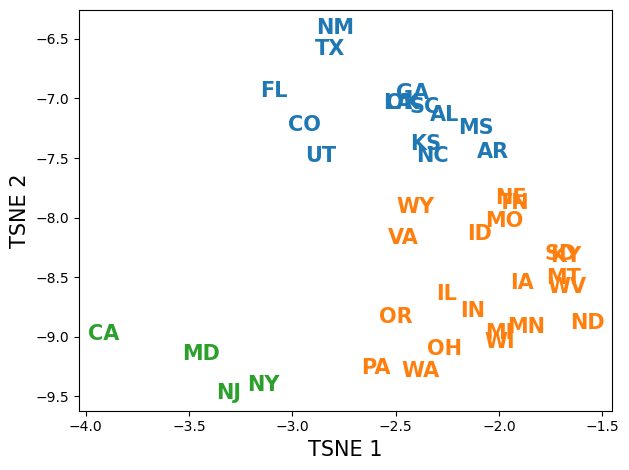

In [48]:
fig, ax = plt.subplots()

ax.scatter(shap_vals_proj[:,0], shap_vals_proj[:,1], alpha=0)

for c in range(3):
    for s, p in zip(np.array(list(shaps.keys()))[clusters==c], shap_vals_proj[clusters==c]):
        ax.text(p[0], p[1], s, fontsize=15, ha='center', va='center', c=plt_colours[c], fontweight='bold')

ax.set_xlabel("TSNE 1", fontsize=15)
ax.set_ylabel("TSNE 2", fontsize=15)

fig.tight_layout()
# fig.savefig("../images/states_clustered_NN.png", dpi=150)

In [63]:
p_val_thresh = 0.01

for c in range(3):
    mask = clusters==c
    states_in_cluster = np.array(list(shaps.keys()))[mask]
    mask = np.in1d(raw_data['state'].to_numpy(), states_in_cluster)
    
    print(f"Cluster {c} with {states_in_cluster}")
    
    for f in features[:11]:
        all_data = raw_data[f].to_numpy()
        in_cluster = all_data[mask]
        
        p_val = ttest_ind(all_data, in_cluster)[1]
        if p_val<p_val_thresh:
            print(f"\t{f}: {all_data.mean():.4f} {in_cluster.mean():.4f} ({(in_cluster.mean() - all_data.mean())/in_cluster.mean()*100:.4f}%)")
    
    print("\n")

Cluster 0 with ['AL' 'AR' 'CO' 'FL' 'GA' 'KS' 'LA' 'MS' 'NM' 'NC' 'OK' 'SC' 'TX' 'UT']
	ACS: % housing units occupied (2016): 82.6144 80.4989 (-2.6280%)
	ACS: % housing units occupied by renters (2016): 28.3520 29.3807 (3.5011%)
	ACS: avg number of years of education (2016): 13.0463 12.8480 (-1.5437%)
	ACS: housing unit density (/mile^2, 2016): 533.5729 374.6271 (-42.4277%)
	ACS: median age: 42.0423 40.8939 (-2.8081%)
	ACS: median household income (inflation adjusted $ in 2016, 2016): 43565.8372 39904.7215 (-9.1746%)
	ACS: racial diversity (Gini Simpson index): 0.2455 0.3377 (27.3172%)
	avg GHI (W/m^2): 186.4701 210.2043 (11.2910%)


Cluster 1 with ['ID' 'IL' 'IN' 'IA' 'KY' 'MI' 'MN' 'MO' 'MT' 'NE' 'ND' 'OH' 'OR' 'PA'
 'SD' 'TN' 'VA' 'WA' 'WV' 'WI' 'WY']
	ACS: % housing units occupied (2016): 82.6144 84.1364 (1.8089%)
	ACS: % housing units occupied by renters (2016): 28.3520 26.9644 (-5.1460%)
	ACS: avg number of years of education (2016): 13.0463 13.1096 (0.4827%)
	ACS: median age: 42

In [64]:
p_val_thresh = 0.05

for c in range(3):
    mask = clusters==c
    states_in_cluster = np.array(list(shaps.keys()))[mask]
    
    print(f"Cluster {c} with {states_in_cluster}")
    
    for i, f in enumerate(features[:10]):
        all_data = shap_vals[:,i]
        in_cluster = all_data[mask]
        
        p_val = ttest_ind(all_data, in_cluster)[1]
        if p_val<p_val_thresh:
            print(f"\t{f}: {all_data.mean():.4f} {in_cluster.mean():.4f} ({in_cluster.mean() - all_data.mean():.4f})")
            
    print("\n")

Cluster 0 with ['AL' 'AR' 'CO' 'FL' 'GA' 'KS' 'LA' 'MS' 'NM' 'NC' 'OK' 'SC' 'TX' 'UT']
	avg GHI (W/m^2): -0.0091 0.1089 (0.1180)


Cluster 1 with ['ID' 'IL' 'IN' 'IA' 'KY' 'MI' 'MN' 'MO' 'MT' 'NE' 'ND' 'OH' 'OR' 'PA'
 'SD' 'TN' 'VA' 'WA' 'WV' 'WI' 'WY']
	ACS: racial diversity (Gini Simpson index): -0.0025 -0.0102 (-0.0077)
	avg GHI (W/m^2): -0.0091 -0.0808 (-0.0717)


Cluster 2 with ['CA' 'MD' 'NJ' 'NY']
	ACS: avg number of years of education (2016): -0.0015 -0.0164 (-0.0148)
	ACS: housing unit density (/mile^2, 2016): 0.0159 0.2078 (0.1919)
	ACS: median household income (inflation adjusted $ in 2016, 2016): 0.0076 0.1086 (0.1010)
	ACS: number of households (2016): 0.0199 0.1915 (0.1717)
	frac_dem_votes: 0.0029 0.0240 (0.0212)




Observations:
- Cluster ['CA' 'MD' 'NJ' 'NY']
    - Richer
    - More racially diverse
    - More democratic
    - A lot denser
    - More susceptible to income and density
- Cluster ['ID' 'IL' 'IN' 'IA' 'KY' 'MI' 'MN' 'MO' 'MT' 'NE' 'ND' 'OH' 'OR' 'PA' 'SD' 'TN' 'VA' 'WA' 'WV' 'WI' 'WY']
    - A lot less diverse
    - Less sunny
    - Lower incentives
    - Less susceptible to GHI
- Cluster ['AL' 'AR' 'CO' 'FL' 'GA' 'KS' 'LA' 'MS' 'NM' 'NC' 'OK' 'SC' 'TX' 'UT']
    - Poorer
    - Less dense
    - More diverse
    - Sunnier
    - Higher incentives
    - More susceptible to GHI

# Graveyard

In [ ]:
rf_space = {
    'n_estimators': Integer(10, 1000),
    'max_depth': Categorical([None, 5, 10, 15, 20, 25, 30, 35, 40]),
    'min_samples_split': Integer(1, 10),
    'min_samples_leaf': Integer(1, 10),
    'criterion': Categorical(["squared_error", "absolute_error", "friedman_mse", "poisson"])
}

rkf = RepeatedKFold(n_splits=5, n_repeats=10)

In [ ]:
rf_opt = BayesSearchCV(RandomForestRegressor(), rf_space, n_iter=50, cv=rkf, n_jobs=8)
rf_opt.fit(X_train, y_train)

print(f"Best CV score: {rf_opt.best_score_:.4f}")
print(f"Test score: {rf_opt.score(X_test, y_test):.4f}")
print(f"Best params: {str(rf_opt.best_params_)}")

In [ ]:
xg_opt = BayesSearchCV(XGBRegressor(n_estimators=100), xg_space, n_iter=20, cv=rkf, n_jobs=8)
xg_opt.fit(X_train, y_train)

print(f"Best CV score: {xg_opt.best_score_:.4f}")
print(f"Test score: {xg_opt.score(X_test, y_test):.4f}")
print(f"Best params: {str(xg_opt.best_params_)}")

## RandomForest

In [ ]:
rf_space = [
    Integer(10, 150, name='n_estimators'),
    Categorical([None, 5, 10, 15, 20, 25, 30, 35, 40], name='max_depth'),
    Integer(2, 10, name='min_samples_split'),
    Integer(1, 10, name='min_samples_leaf'),
    Categorical(["squared_error", "absolute_error", "friedman_mse", "poisson"], name='criterion')
]

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10)

def objective_rf(x):
    params = {v: xv for v, xv in zip([v.name for v in rf_space], x)}
    model = RandomForestRegressor(**params)
    # scores = cross_val_score(model, X_train, y_train, cv=rskf, n_jobs=8)
    scores = Parallel(n_jobs=8)(delayed(cv_one)(model, X_train, y_train, train, test) for train, test in rskf.split(X_train, y_train!=0))
    
    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [ ]:
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
rf_opt = gp_minimize(objective_rf, rf_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_RF.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

In [ ]:
rf_opt = load(f"opt_results_RF.pkl")

In [ ]:
best_x = rf_opt.x_iters[rf_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in rf_space], best_x)}
model = RandomForestRegressor(**best_params, n_jobs=8)
model.fit(X_train, y_train)

print(f"Best CV score: {-rf_opt.func_vals.min():.4f}")
print(f"Test score: {model.score(X_test, y_test):.4f}")
print(f"Best params: {str(best_params)}")

In [ ]:
_ = plot_convergence(rf_opt)
plt.show()

In [ ]:
_ = plot_objective(rf_opt)
plt.show()

## NN

In [ ]:
# good set of parameters: lr=0.0014, 50, 0, 'relu', False

def get_model():
    return build_model(50, 0, 'relu', False)

# def get_model():
    # return build_model(100, 50, 'relu', False)

model = get_model()
model_parameters = filter(lambda p: p.requires_grad, model.parameters())
print(f"Total number of trainable parameters: {sum([np.prod(p.size()) for p in model_parameters])}")

In [ ]:
lr = 0.0014
n_epochs = 500

model = get_model()

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=lr, n_epochs=n_epochs, verbose=True)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(train_losses, label="Train losses")
ax[0].plot(val_losses, label="Validation losses")

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

ax[1].plot(train_r2, label="Train R2")
ax[1].plot(val_r2, label="Validation R2")

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

In [ ]:
X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

model = get_model()

n_epochs = 500

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=lr, n_epochs=n_epochs, verbose=True)
print(f"Final test R2: {val_r2[-1]:.4f}")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(train_losses, label="Train losses")
ax[0].plot(val_losses, label="Test losses")

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

ax[1].plot(train_r2, label="Train R2")
ax[1].plot(val_r2, label="Test R2")

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

In [32]:
def one_train(model):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y!=0)

    X_scaler = StandardScaler().fit(X_train)
    X_train_t = X_scaler.transform(X_train)
    X_train_v = X_scaler.transform(X_test)

    y_scaler = StandardScaler().fit(y_train)
    y_train_t = y_scaler.transform(y_train)
    y_train_v = y_scaler.transform(y_test)
    
    _, train_loss, val_loss, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=False)

n = 50
n_epochs = 500
train_losses = []
val_losses = []
train_r2s = []
val_r2s = []

timer = IterTimer(n)

for _ in range(n):
    timer.start_iter()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y!=0)

    X_scaler = StandardScaler().fit(X_train)
    X_train_t = X_scaler.transform(X_train)
    X_train_v = X_scaler.transform(X_test)

    y_scaler = StandardScaler().fit(y_train)
    y_train_t = y_scaler.transform(y_train)
    y_train_v = y_scaler.transform(y_test)

    model = BestSVI().to(device)
    model, train_loss, val_loss, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=False)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_r2s.append(train_r2)
    val_r2s.append(val_r2)
    timer.end_iter()
    
train_losses = np.array(train_losses)
val_losses = np.array(val_losses)
train_r2s = np.array(train_r2s)
val_r2s = np.array(val_r2s)

Iteration 50/50, ETA: 17:58:53 (average time per iteration: 14.211s)
